# USER PARAMETERS

**Question.** What is the Fredholm lens \(\mathcal L_\nu\), and which \(\nu\) belongs to a selected local stratum?

Edit the next cell, then use **Restart Kernel → Run All**. The script exports vector PDF, PNG, GIF, and MP4. The moving dot follows \(x\mapsto\mu_\nu(x)\); the navy endpoints are the limits \(0\) and \(1\).

Primary source: [Karlovich (2025), (5.5)–(5.7) and (6.5)](https://doi.org/10.1007/s40590-025-00781-1).

In [1]:
# ============================================================
# USER PARAMETERS
# ============================================================

P = 2.0
DELTA = -0.15
STRATUM = "zero_fiber"  # zero_fiber | finite_t | infinity_finite_eta | infinity_endpoint
MARKER_X = 0.4
X_EXTENT = 3.5
N_FRAMES = 72
FPS = 12
SHOW_REFLECTION = True
OUTPUT_NAME = "fredholm_symbol_curve"


## Mathematical checkpoint

For \(1<p<\infty\) and \(-1/p<\delta<1-1/p\),
\(\nu_M=1/p+\delta\) lies in \((0,1)\). Formula (5.5) defines
\[
\mu_\nu(x)=\frac{1+\coth[\pi(x+i\nu)]}{2},\qquad
\mathcal L_\nu=\{\mu_\nu(x):x\in\overline{\mathbb R}\}.
\]

| Selected stratum | Parameter plotted | Mathematical scope |
|---|---|---|
| zero_fiber | \(\nu_M=1/p+\delta\) | Final (6.5) at \(M_0\); \(x\) is active. |
| finite_t | \(1/p\) | Auxiliary half-line test (5.7); final (6.6)–(6.7) is independent of \(x\). |
| infinity_finite_eta | \(\nu_M\) | Half-line (5.7) after (5.6), final (6.5) retains \(x\); the original whole-line (4.4) uses \(1/q-\delta=1-\nu_M\). |
| infinity_endpoint | endpoints only | Final (6.5) fixes \(x=\pm\infty\), so only \(0\) and \(1\) remain. |

The dashed arc displays the exact reflection
\(\mu_\nu(-x)=1-\mu_{1-\nu}(x)\) from (5.6); it is not an extra local stratum.

In [2]:
from pathlib import Path
import platform
import sys
import numpy as np
import matplotlib
from IPython.display import Markdown, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
script_path = project_root / "src" / "render_symbol_curve.py"
assert script_path.exists(), f"Missing companion script: {script_path}"
sys.path.insert(0, str(script_path.parent))

from render_symbol_curve import SymbolCurveParams, mu_nu, render_assets, verify_identity

assert sys.version_info[:3] == (3, 12, 2), sys.version
params = SymbolCurveParams(
    p=P, delta=DELTA, stratum=STRATUM, marker_x=MARKER_X,
    x_extent=X_EXTENT, frames=N_FRAMES, fps=FPS,
    show_reflection=SHOW_REFLECTION,
)
params.validate()
checks = verify_identity(params)
assert 0 < params.nu < 1
display(Markdown(
    f"**Selected stratum:** {STRATUM}; "
    f"$\\nu={params.nu:.3f}$, $1-\\nu={params.reflected_nu:.3f}$. "
    + params.interpretation
))
print("Python:", sys.executable, sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print("Numerical checks:", checks)


**Selected stratum:** zero_fiber; $\nu=0.350$, $1-\nu=0.650$. The final zero-fiber symbol uses x in extended R and nu = 1/p + delta.

Python: /home/enriquedo/.pyenv/versions/3.12.2/bin/python 3.12.2
Platform: Linux-6.8.0-138-generic-x86_64-with-glibc2.35
NumPy: 2.4.6 Matplotlib: 3.10.9
Numerical checks: {'reflection_error': 2.3556123656502583e-16, 'left_endpoint_error': 0.0, 'right_endpoint_error': 0.0}


<!-- resultado-verificado: render_symbol_curve -->

## Trace the arc

The solid magenta curve is the selected \(\mathcal L_\nu\).
The moving ring is \(\mu_\nu(x)\), and the current \(x\) is visible
in every frame. The navy points mark exact limits \(0\) and \(1\).
For the endpoint stratum the animation alternates between the two
endpoint values and omits an active arc.

The PDF is a vector snapshot at the selected marker value.
All four files are generated by the [companion render script](../src/render_symbol_curve.py).

pdf: outputs/fredholm_symbol_curve.pdf (29,401 bytes)
png: outputs/fredholm_symbol_curve.png (56,945 bytes)
gif: outputs/fredholm_symbol_curve.gif (1,955,481 bytes)
mp4: outputs/fredholm_symbol_curve.mp4 (52,789 bytes)


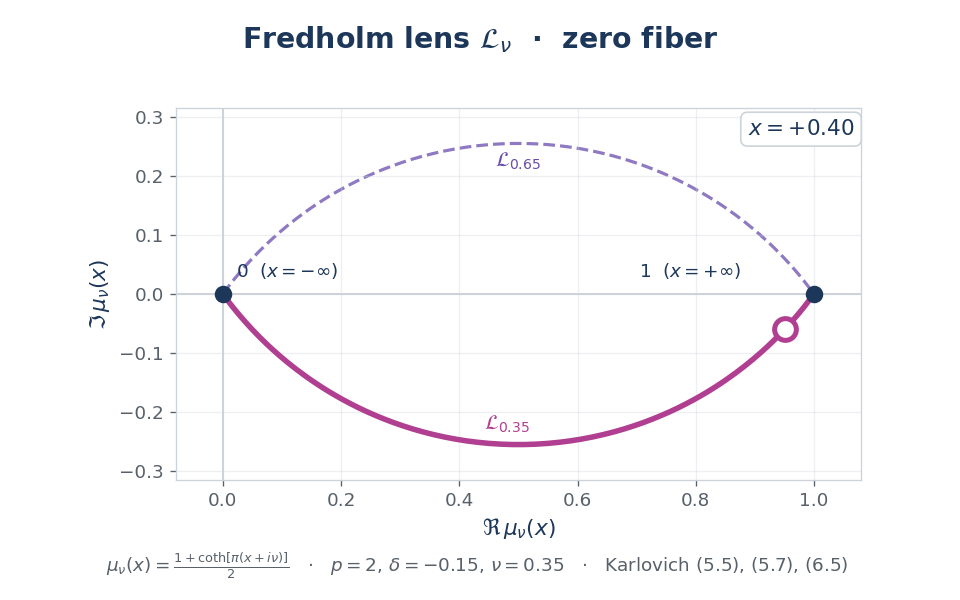

In [3]:
from IPython.display import Image

output_dir = project_root / "outputs"
assets = render_assets(params, output_dir, OUTPUT_NAME)
for kind, path in assets.items():
    print(f"{kind}: {path.relative_to(project_root)} ({path.stat().st_size:,} bytes)")
display(Image(filename=str(assets["png"])))


In [4]:
assert set(assets) == {"pdf", "png", "gif", "mp4"}
assert all(path.exists() and path.stat().st_size > 0 for path in assets.values())
assert abs(mu_nu(-0.7, params.nu) - (1 - mu_nu(0.7, 1-params.nu))) < 1e-12
print("Exports and reflection identity verified.")


Exports and reflection identity verified.


## Interpretation

As \(x\) increases, \(\mu_\nu(x)\) moves from \(0\) to \(1\).
For \(\nu=1/2\), the lens is the real interval.
The reflected exponent \(1-\nu\) mirrors the curve through \(1/2\)
by (5.6). The Fredholm criterion evaluates a finite matrix symbol at
every point of \(\widehat\Omega\); one plotted arc is one local ingredient
of that test.

Try changing DELTA while retaining \(-1/P<\mathrm{DELTA}<1-1/P\).
Then compare the solid and dashed arcs and select infinity_endpoint
to inspect the last stratum.